In [63]:
import numpy as np
import pandas as pd
from nltk.classify import NaiveBayesClassifier
from nltk.corpus import subjectivity
from nltk.sentiment import SentimentAnalyzer
from nltk.sentiment.util import *

import numpy as np 
import pandas as pd 
#pd.set_option('display.max_colwidth', -1)
from time import time
import re
import string
import os
from pprint import pprint
import collections

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")
sns.set(font_scale=1.3)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
#from sklearn.externals import joblib
import joblib as jb

#import gensim

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

import warnings
warnings.filterwarnings('ignore')

np.random.seed(37)


In [64]:
# Reading the saved data pickle file
df  = pd.DataFrame()
df = pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/pickled_filtered_lead_para_sp500_clean.pkl', compression=None)
df_sentiment=pd.read_pickle('/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/data/pkl/sentiment.pkl', compression=None)
df_vix_2010_2021=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')

In [65]:
df["articles"].describe()
df = df.join(df_sentiment)
df["vix"] = df["adj close"]#.apply(np.int)
df["vix_ln_return"]=np.log(df["vix"]/df["vix"].shift(1))
df['sentiment'] = df[["sentiment"]].apply(pd.to_numeric)
df["sentiment_ewm"]=df["sentiment"].ewm(10).mean()
df["date"]=df.index
# df['date'] = pd.date_range(start='25/9/2019', periods=len(df), freq='D')
df_part1 = df.loc['2019-09-25':'2020-02-14']
df_part2 = df.loc['2020-02-15':'2020-05-31']
df_part3 = df.loc['2020-06-01':'2021-07-15']

AttributeError: 'numpy.ndarray' object has no attribute 'plot'

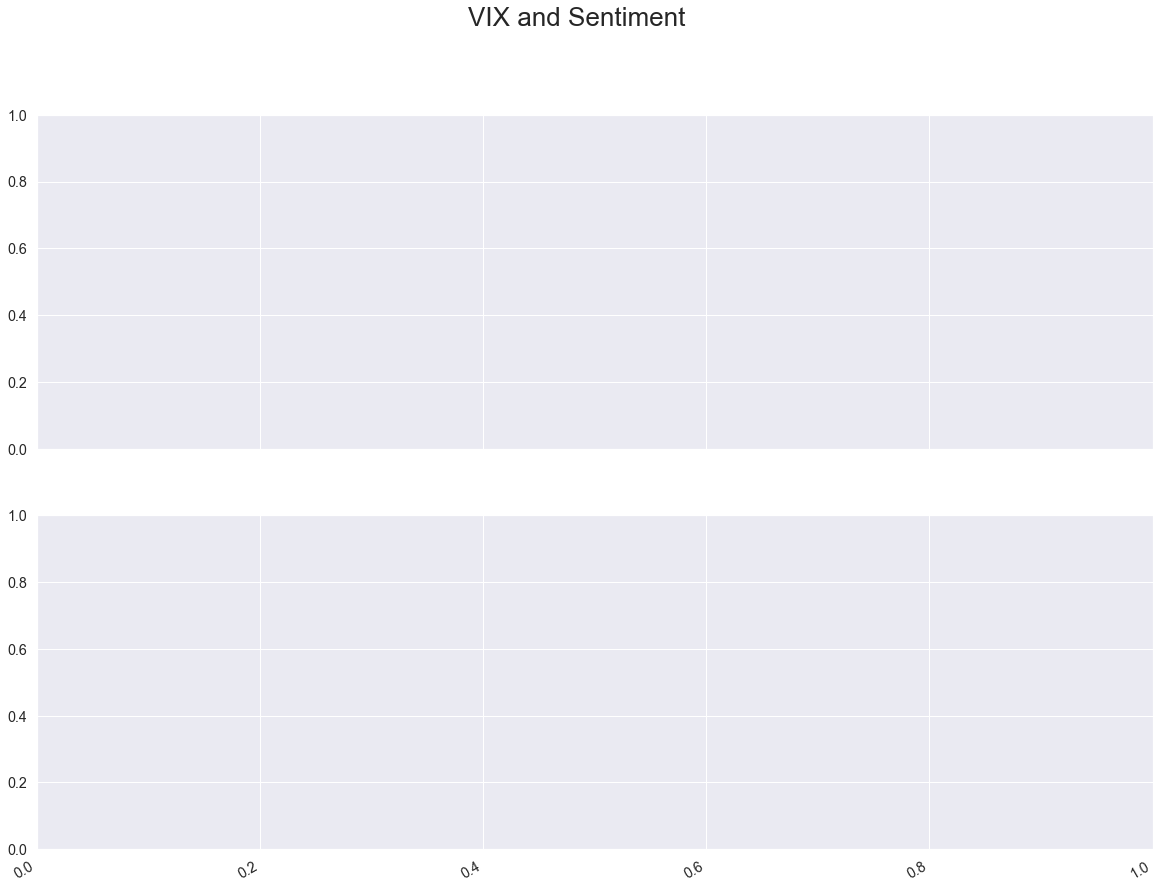

In [135]:
plt.sub
fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()

# axs.set_ylabel("VIX", size=20)
labels=['2019-09-14 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']
# axs.set_ylabel("sentiment", size=20)
# axs.plot(df[['sentiment']])

# axs.legend([l1], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))
axs.plot(df[['vix']])

plt.plot(df[['sentiment']])

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots.png")
plt.show()

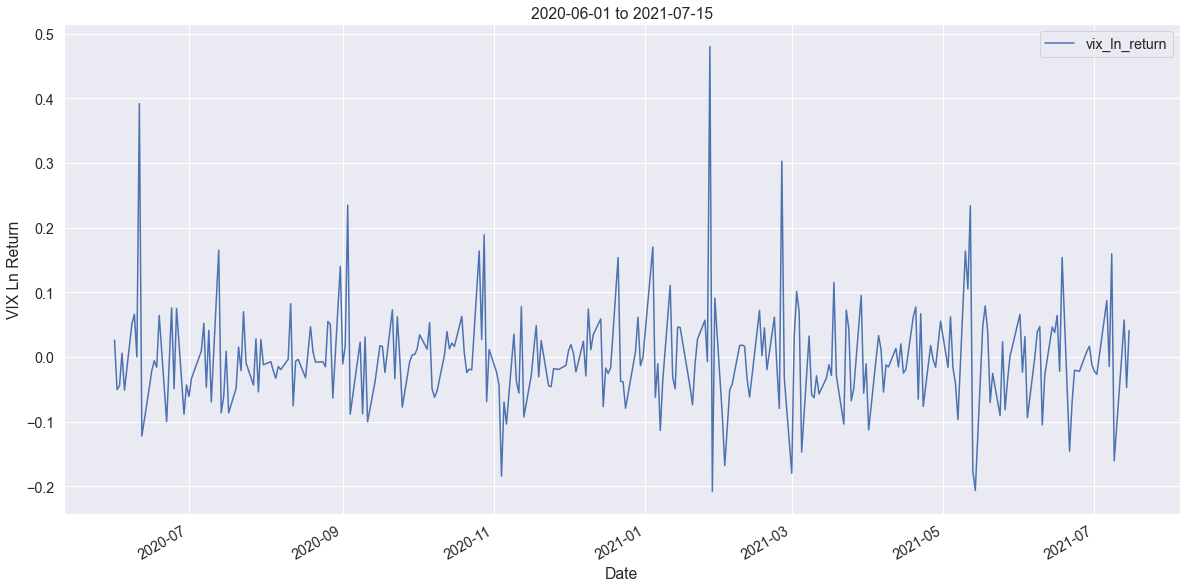

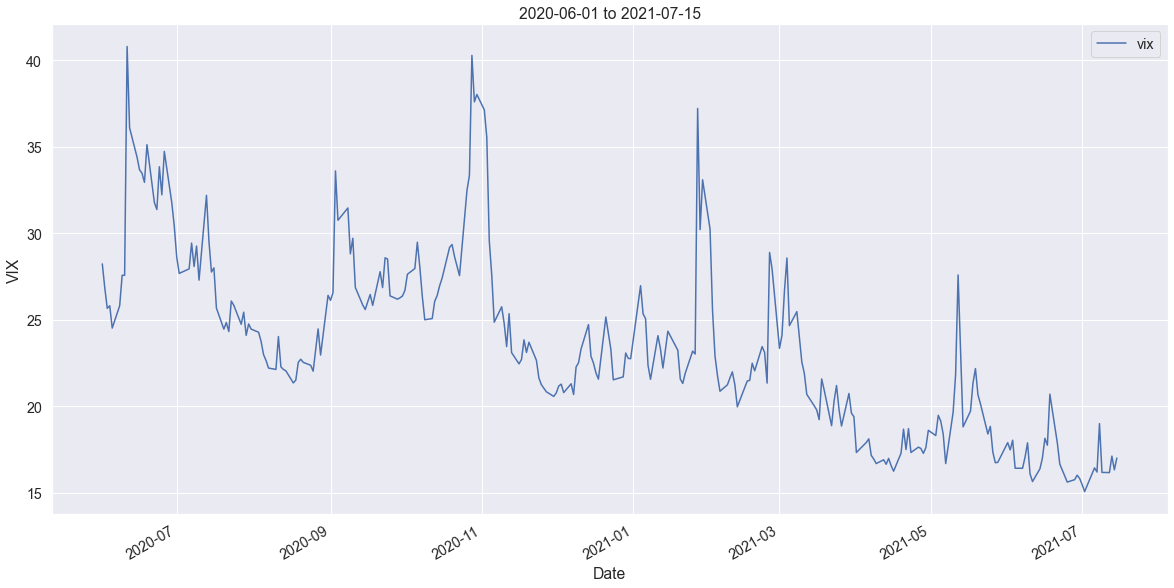

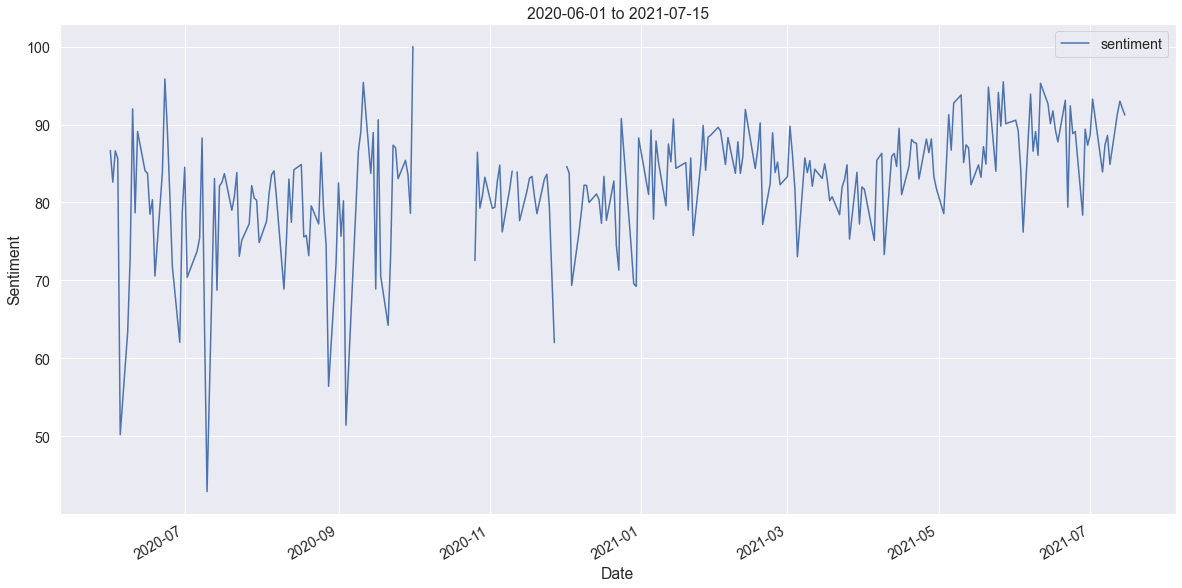

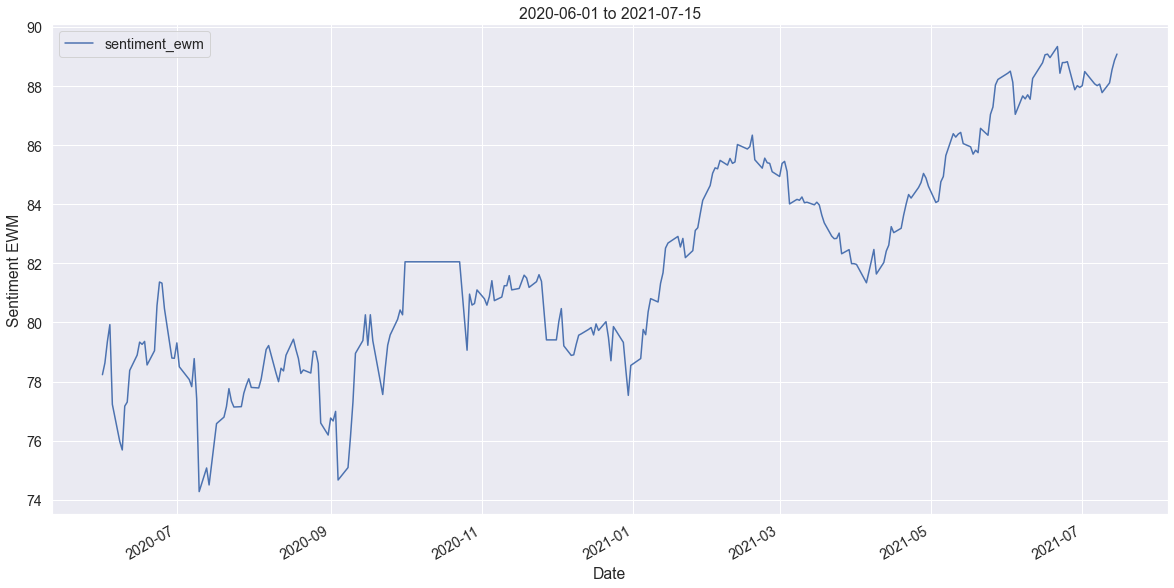

In [89]:
dfplot = df_part3[['vix_ln_return']].plot(figsize=(20, 10),title='2020-06-01 to 2021-07-15')
dfplot.set_ylabel("VIX Ln Return")
dfplot.set_xlabel("Date")
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/vix_ln_return.png")

dfplot = df_part3[['vix']].plot(figsize=(20, 10),title='2020-06-01 to 2021-07-15')
dfplot.set_ylabel("VIX")
dfplot.set_xlabel("Date")
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/vix.png")

dfplot = df_part3[['sentiment']].plot(figsize=(20, 10),title='2020-06-01 to 2021-07-15')
dfplot.set_ylabel("Sentiment")
dfplot.set_xlabel("Date")
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/sentiment.png")

dfplot = df_part3[['sentiment_ewm']].plot(figsize=(20, 10),title='2020-06-01 to 2021-07-15')
dfplot.set_ylabel("Sentiment EWM")
dfplot.set_xlabel("Date")
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/sentiment_ewm.png")

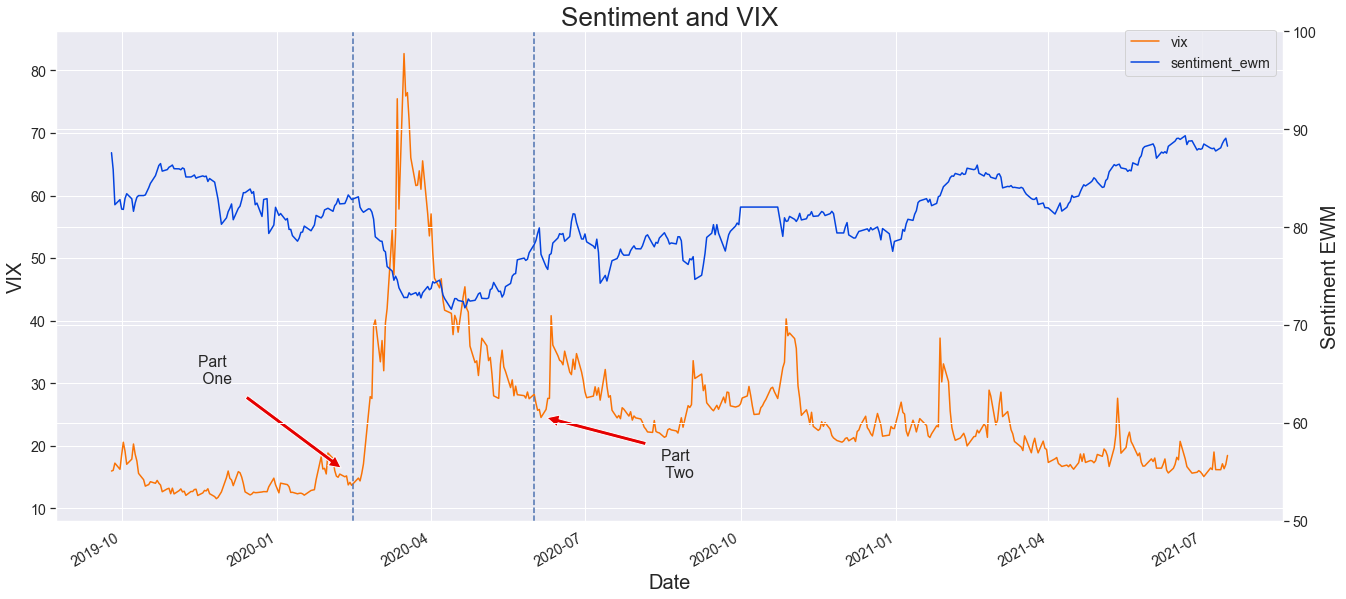

In [110]:
import matplotlib.pyplot as plt
import datetime as dt
import matplotlib.dates as mdates
# df1 = df
# idx = pd.date_range('2019-09-25', '2021-07-15')
# df1.index = pd.DatetimeIndex(df1.index)
# df1 = df1.reindex(idx, fill_value=np.NaN)


######### GRAPH LABELS #########            

fig, ax1 = plt.subplots(figsize=(22,10))
l1 = ax1.plot(df[['vix']], color='#f97306')
ax1.set_xlabel("Date",fontsize=20)
ax1.set_title("Sentiment and VIX", size=26)
ax1.set_ylabel("VIX", size=20)
ax2 = ax1.twinx()
l2 = ax2.plot(df[['sentiment_ewm']], color='#0343DF')# color='#3776AB' BLUE ORIG)
ax2.set_ylim([50, 100])
ax2.set_ylabel("Sentiment EWM", size=20)

labels=['vix', 'sentiment_ewm']
fig.legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))
############ Arrows ############            

starting_date0 = dt.datetime(2019, 11, 15)
starting_date1 = mdates.date2num(starting_date0)
pointing_arrow =dt.datetime(2020, 2, 15)
pointing_arrow1 = mdates.date2num(pointing_arrow)
ax1.annotate('Part \n One', xy=(pointing_arrow1, 15), xytext=(starting_date1,30),
            arrowprops=dict(facecolor='#e50000', shrink=0.1))

starting_date2 = dt.datetime(2020, 8, 15)
starting_date3 = mdates.date2num(starting_date2)
pointing_arrow3 =dt.datetime(2020, 6, 1)
pointing_arrow4 = mdates.date2num(pointing_arrow3)
ax1.annotate('Part \n Two', xy=(pointing_arrow4, 25), xytext=(starting_date3,15),
            arrowprops=dict(facecolor='#e50000', shrink=0.1))

######### VERTICAL LINES #########            

starting_date0 = dt.datetime(2020, 2, 15)
starting_date1 = mdates.date2num(starting_date0)
ax1.axvline(starting_date1, 0, 1, color='b', linestyle='--')
starting_date2 = dt.datetime(2020, 6, 1)
starting_date3 = mdates.date2num(starting_date2)
ax1.axvline(starting_date3, 0, 1, color='b', linestyle='--')

########### PLOT GRAPHS ###########            

fig.autofmt_xdate()
fig = ax2.get_figure()

#fig.savefig("/Users/Farid Srouji/Documents/Research/VIXInterplaySentiment/master/financialmodelingprep/images/sentimentVIX.png")

# PART THREE ONLY: 2020-06-01 to 2021-07-15

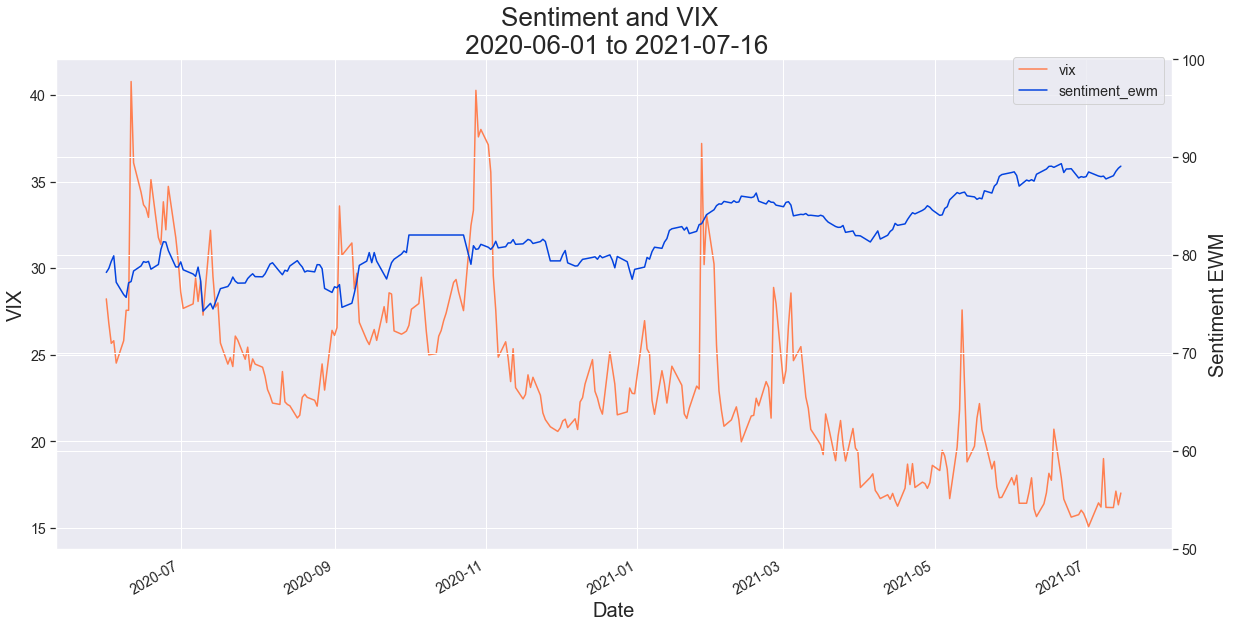

In [112]:
fig, ax1 = plt.subplots(figsize=(20,10))
l1 = ax1.plot(df_part3['vix'], color='#ff7f50')
ax1.set_xlabel("Date",fontsize=20)
ax1.set_title("Sentiment and VIX \n 2020-06-01 to 2021-07-16", size=26)
ax1.set_ylabel("VIX", size=20)

ax2 = ax1.twinx()
l2 = ax2.plot(df_part3['sentiment_ewm'], color='#0343DF')# color='#e50000')
ax2.set_ylim([50, 100])
ax2.set_ylabel("Sentiment EWM", size=20)

labels=['vix', 'sentiment_ewm']
fig.legend([l1, l2], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

fig.autofmt_xdate()
fig = ax2.get_figure()

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/sentimentVIXpart3.png")

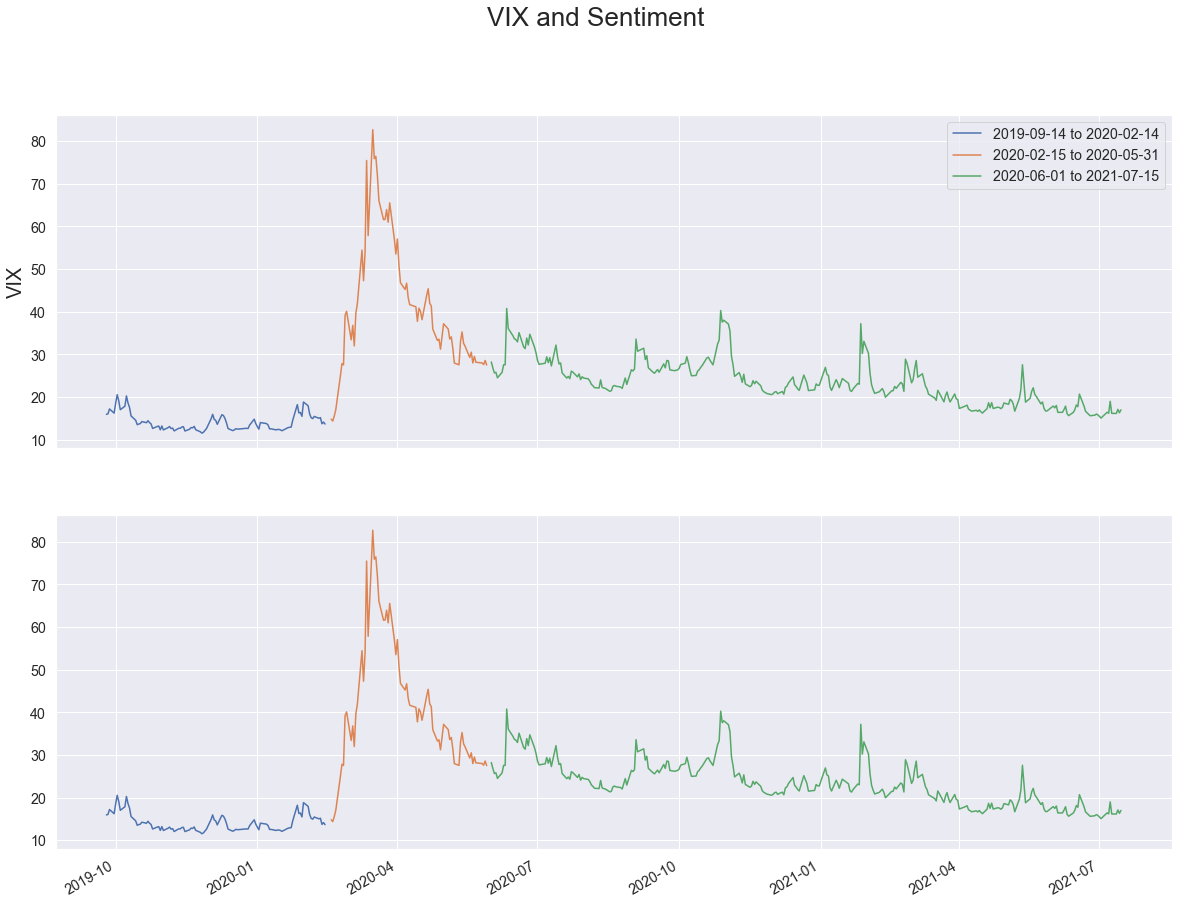

In [137]:
fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()

axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-14 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df_part1[['vix']])
l2 = axs[0].plot(df_part2[['vix']])
l3 = axs[0].plot(df_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

plt.plot(df_part1[['vix']])
plt.plot(df_part2[['vix']])
plt.plot(df_part3[['vix']])
plt.axvspan(x='2020-02-15', color='b', linestyle='--')
starting_date = dt.datetime(2020, 2, 15)
starting_date1 = mdates.date2num(starting_date)
axs[0].axvline(starting_date1, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date1, 0, 1, color='b', linestyle='--')

starting_date2 = dt.datetime(2020, 6, 1)
starting_date3 = mdates.date2num(starting_date2)
axs[0].axvline(starting_date3, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date3, 0, 1, color='b', linestyle='--')

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots.png")
plt.show()

# import datetime
# start_date = datetime.datetime(2020, 2, 15)
# end_date = datetime.datetime(2020, 6, 1)
# plt.axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)
# fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots2.png")
# plt.show()

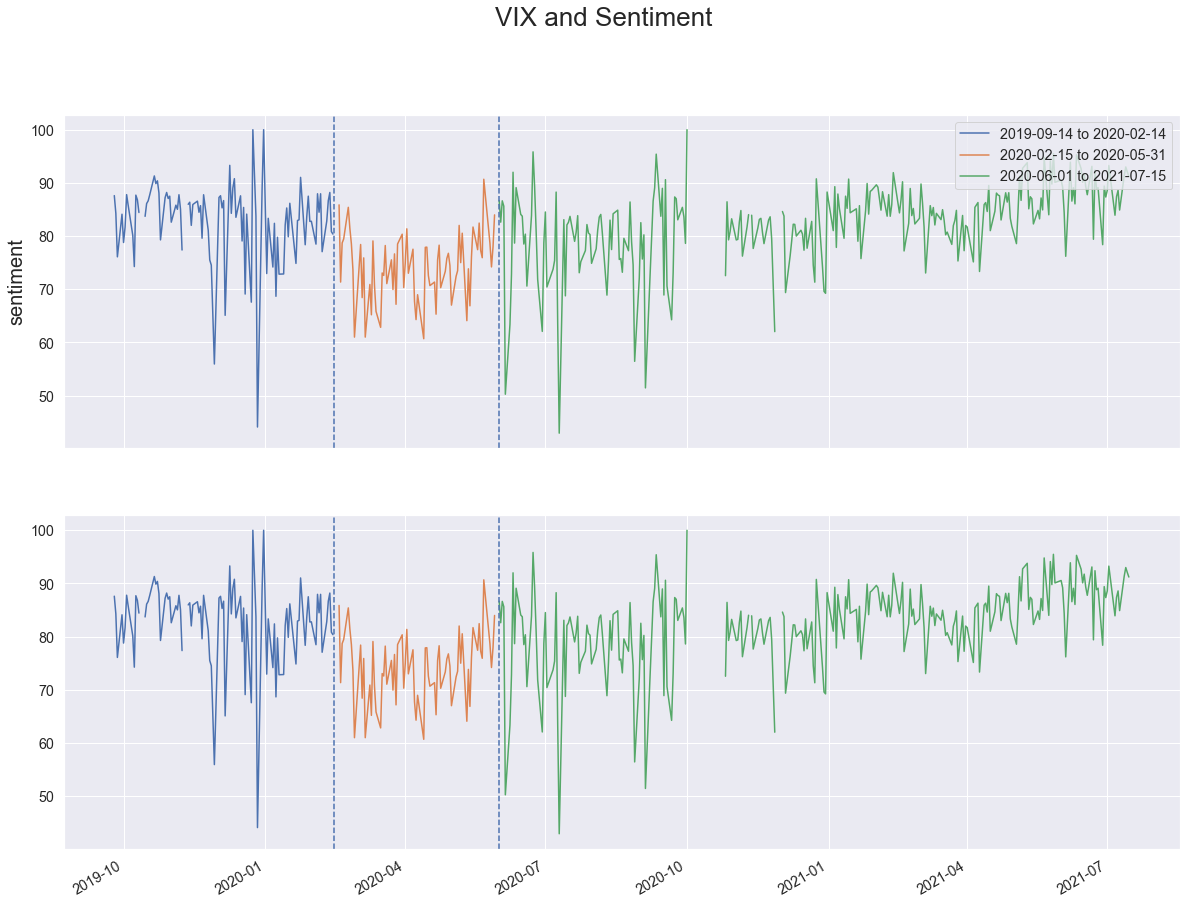

In [127]:
fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()

axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-14 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']
axs[0].set_ylabel("sentiment", size=20)
l1 = axs[0].plot(df_part1[['sentiment']])
l2 = axs[0].plot(df_part2[['sentiment']])
l3 = axs[0].plot(df_part3[['sentiment']])

axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

# axs[1].set_ylabel("Sentiment EWM", size=20)
# axs[1].plot(df1_part1[['sentiment_ewm']])
# axs[1].plot(df1_part2[['sentiment_ewm']])
# axs[1].plot(df1_part3[['sentiment_ewm']])
# axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

# axs[0].set_ylabel("Sentiment", size=20)
# axs[0].plot(df_part1[['sentiment']])
# axs[0].plot(df_part2[['sentiment']])
# axs[0].plot(df_part3[['sentiment']])

plt.plot(df_part1[['sentiment']])
# plt.subplot(122)
plt.plot(df_part2[['sentiment']])
#plt.subplot(123)
plt.plot(df_part3[['sentiment']])
# plt.axvspan(x='2020-02-15', color='b', linestyle='--')
starting_date = dt.datetime(2020, 2, 15)
starting_date1 = mdates.date2num(starting_date)
axs[0].axvline(starting_date1, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date1, 0, 1, color='b', linestyle='--')

starting_date2 = dt.datetime(2020, 6, 1)
starting_date3 = mdates.date2num(starting_date2)
axs[0].axvline(starting_date3, 0, 1, color='b', linestyle='--')
plt.axvline(starting_date3, 0, 1, color='b', linestyle='--')

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots.png")
plt.show()

# import datetime
# start_date = datetime.datetime(2020, 2, 15)
# end_date = datetime.datetime(2020, 6, 1)
# plt.axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)
# fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots2.png")
# plt.show()

In [ ]:
df1_part1 = df_part1
df1_part2 = df_part2
df1_part3 = df_part3

idx = pd.date_range('2019-09-25', '2020-02-14')
df1_part1.index = pd.DatetimeIndex(df1_part1.index)
df1_part1 = df1_part1.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-02-15', '2020-05-31')
df1_part2.index = pd.DatetimeIndex(df1_part2.index)
df1_part2 = df1_part2.reindex(idx, fill_value=np.NaN)
idx = pd.date_range('2020-06-01', '2021-07-15')
df1_part3.index = pd.DatetimeIndex(df1_part3.index)
df1_part3 = df1_part3.reindex(idx, fill_value=np.NaN)

fig, axs = plt.subplots(2,figsize=(20,15))
fig.suptitle('VIX and Sentiment', size=26)
fig.autofmt_xdate()

axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-25 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df1_part1[['vix']])
l2 = axs[0].plot(df1_part2[['vix']])
l3 = axs[0].plot(df1_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

axs[1].set_ylabel("Sentiment EWM", size=20)
axs[1].plot(df1_part1[['sentiment_ewm']])
axs[1].plot(df1_part2[['sentiment_ewm']])
axs[1].plot(df1_part3[['sentiment_ewm']])
axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

import datetime
start_date = datetime.datetime(2019, 9, 25)
end_date = datetime.datetime(2020, 2, 14)

start_date1 = datetime.datetime(2020, 2, 15)
end_date1 = datetime.datetime(2020, 6, 1)

plt.axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)
axs[0].axvspan(start_date, end_date, color='g', alpha=0.5, lw=0)

plt.axvspan(start_date1, end_date1, color='b', alpha=0.5, lw=0)
axs[0].axvspan(start_date1, end_date1, color='b', alpha=0.5, lw=0)

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots2.png")
plt.show()

In [ ]:
fig, axs = plt.subplots(2,figsize=(25,15))
fig.suptitle(' \n VIX and Sentiment Interplay', size=26)
fig.autofmt_xdate()

axs[0].set_ylabel("VIX", size=20)
labels=['2019-09-25 to 2020-02-14', '2020-02-15 to 2020-05-31', '2020-06-01 to 2021-07-15']

l1 = axs[0].plot(df_part3[['vix']])
axs[0].legend([l1, l2, l3], labels=labels, loc='upper right')#, bbox_to_anchor='upper right')#(0.99, 0.85))

axs[1].set_ylabel("Sentiment EWM", size=20)

axs[1].plot(df_part3[['sentiment_ewm']])
axs[1].legend([l1, l2, l3], labels=labels, loc='lower right')#, bbox_to_anchor=(0.99, 0.2))

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/VIXandSentimentSubplots3.png")
plt.show()

In [116]:
# Import Data
df_vix_2010_2021=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_options=pd.read_csv('/Users/Farid Srouji/Documents/Research/master/globaldata/vix_2010_2021.csv')
df_vix_2010_2021['Date']= pd.to_datetime(df_vix_2010_2021['Date'])
df_vix_2010_2021.index= df_vix_2010_2021['Date']
print("df_vix_2010_2021['Date']="+str(type(df_vix_2010_2021['Date'])))
print("df_part3['Date']="+str(type(df_part3['date'])))

df_vix_2010_2021["vix"] = df_vix_2010_2021["Adj Close"]#.apply(np.int)
df_vix_2010_2021["vix_ln_return"]=np.log(df_vix_2010_2021["vix"]/df_vix_2010_2021["vix"].shift(1))

import datetime as dt
from datetime import date
import calendar
my_date = date.today()
calendar.day_name[my_date.weekday()] 

df_vix_2010_2021['year'] = [d.year for d in df_vix_2010_2021.Date]
df_vix_2010_2021['month'] = [d.strftime('%b') for d in df_vix_2010_2021.Date]
df_vix_2010_2021['day'] = [d for d in df_vix_2010_2021.index.day_name()]
years = df_vix_2010_2021['year'].unique()
df_vix_2010_2021['month-year'] = [d.strftime('%b') + str(d.year) for d in df_vix_2010_2021.Date]

df_vix_2010_2021['Date']=<class 'pandas.core.series.Series'>
df_part3['Date']=<class 'pandas.core.series.Series'>


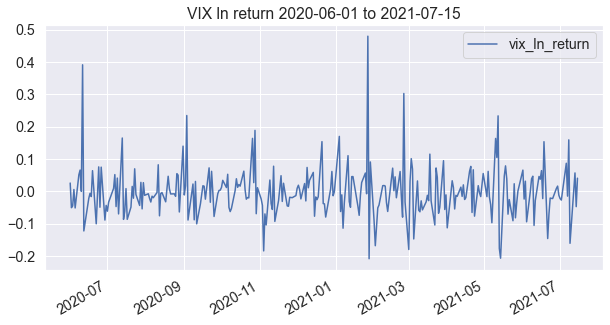

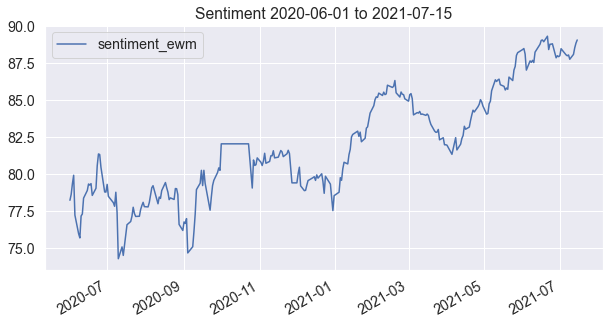

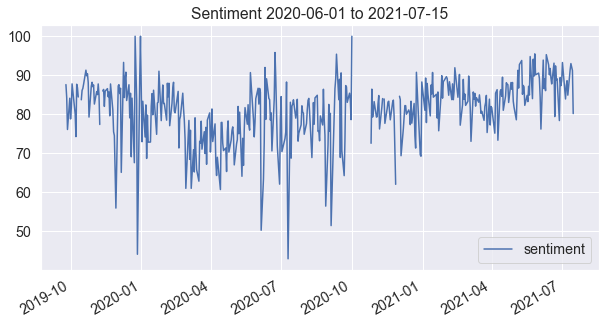

In [117]:
dfplot = df_part3[['vix_ln_return']].plot(figsize=(10, 5),title='VIX ln return 2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/vix_ln_return.png")

fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/sentiment.png")
df_part3[['sentiment_ewm']].plot(figsize=(10, 5),title='Sentiment 2020-06-01 to 2021-07-15')
fig.savefig("/Users/Farid Srouji/Documents/Research/master/financialmodelingprep/images/sentiment_ewm.png")
dfplot = df[['sentiment']].plot(figsize=(10, 5),title='Sentiment 2020-06-01 to 2021-07-15')
fig = dfplot.get_figure()

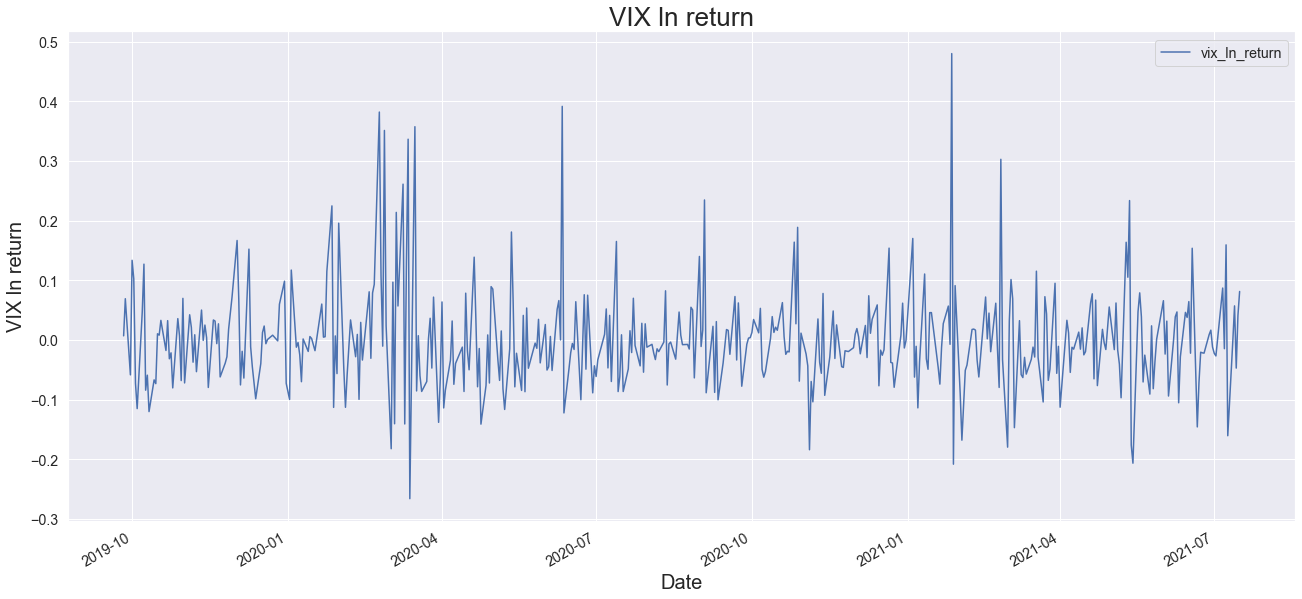

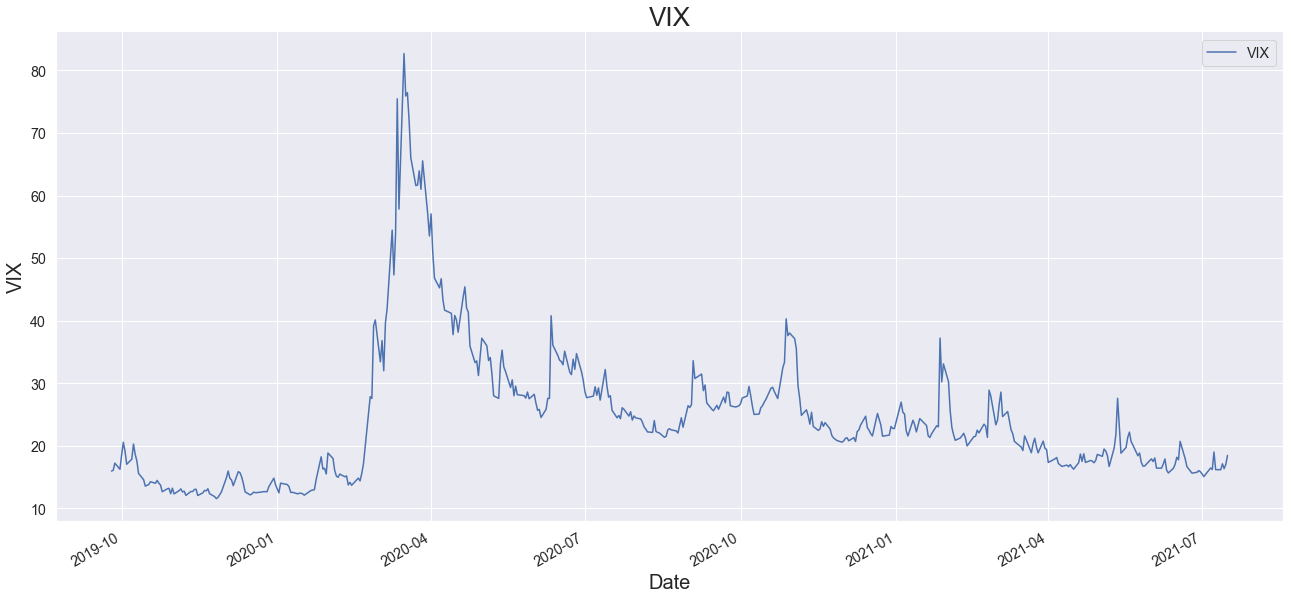

In [118]:
import matplotlib.pyplot as plt
import datetime as dt
import matplotlib.dates as mdates
df1 = df
# idx = pd.date_range('2019-09-25', '2021-07-15')
# df1.index = pd.DatetimeIndex(df1.index)
# df1 = df1.reindex(idx, fill_value=np.NaN)

fig, ax1 = plt.subplots(figsize=(22,10))
l1 = ax1.plot(df1[['vix_ln_return']])# color='#f97306')

ax1.set_xlabel("Date",fontsize=20)
ax1.set_title("VIX ln return", size=26)
ax1.set_ylabel("VIX ln return", size=20)

labels=['vix_ln_return', 'sentiment']
fig.legend([l1], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

fig.autofmt_xdate()
fig = ax1.get_figure()
fig, ax1 = plt.subplots(figsize=(22,10))
l1 = ax1.plot(df1[['vix']])# color='#f97306')
ax1.set_xlabel("Date",fontsize=20)
ax1.set_title("VIX", size=26)
ax1.set_ylabel("VIX", size=20)

labels=['VIX', 'sentiment']
fig.legend([l1], labels=labels, loc='right', bbox_to_anchor=(0.9, 0.85))

fig.autofmt_xdate()
fig = ax1.get_figure()